# 2. Non-competitive demand in pricing, wash trading, revenue
BLUEPRINT §4.2 and §8 (2026-10-23).

In [1]:
import csv
from pathlib import Path
OUT = Path("../out")

def load(name):
    """rows of out/<name>.csv as dicts (numbers stay strings; use f())"""
    with open(OUT / f"{name}.csv") as fh:
        return list(csv.DictReader(fh))

def f(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return x

def show(rows, cols=None, limit=40, where=None):
    """print rows as an aligned table"""
    if where:
        rows = [r for r in rows if where(r)]
    rows = rows[:limit]
    if not rows:
        print("(no rows)"); return
    cols = cols or list(rows[0].keys())
    def fmt(v):
        try:
            x = float(v)
            return f"{x:,.4g}" if abs(x) < 1e6 else f"{x:,.0f}"
        except (TypeError, ValueError):
            return str(v)
    cells = [[fmt(r.get(c, "")) for c in cols] for r in rows]
    w = [max(len(c), *(len(row[i]) for row in cells)) for i, c in enumerate(cols)]
    print(" | ".join(c.ljust(w[i]) for i, c in enumerate(cols)))
    print("-+-".join("-" * x for x in w))
    for row in cells:
        print(" | ".join(v.rjust(w[i]) for i, v in enumerate(row)))

def svg(name):
    """display a pre-rendered chart from out/plots"""
    p = OUT / "plots" / name
    try:
        from IPython.display import SVG, display
        display(SVG(filename=str(p)))
    except Exception:
        print(f"[chart: {p}]")

## Non-competitive buy budget vs. P*
Under v0.7 the retail budget never trades when the competitive book crosses exactly (no leftovers). Under v0.8 it enters the demand curve, capped at 50 % of the competitive volume, and lifts P* (lowers the borrow rate) while displacing competitive lenders.

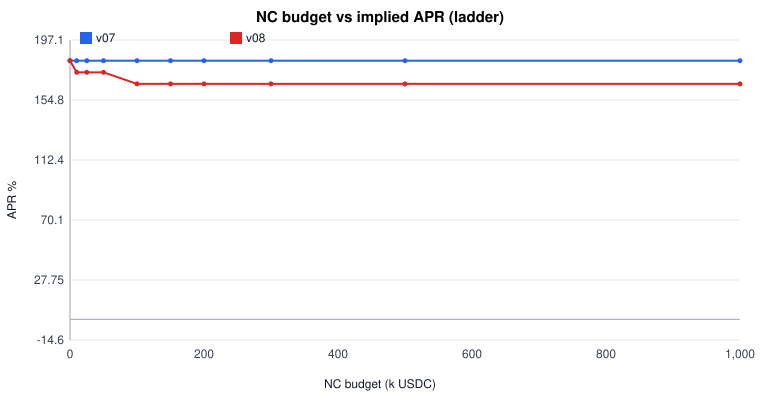

In [2]:
svg("nc_pricing_ladder.svg")  # ladder book

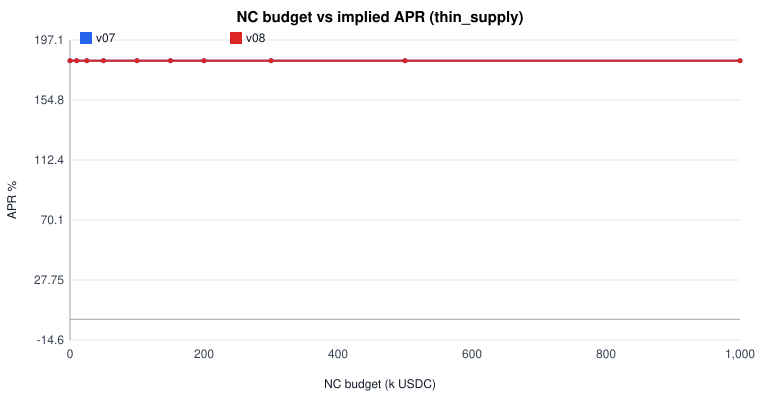

In [3]:
svg("nc_pricing_thin_supply.svg")  # thin supply

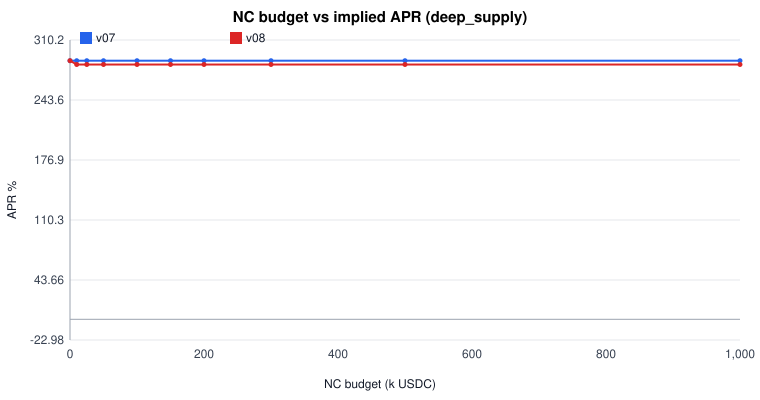

In [4]:
svg("nc_pricing_deep_supply.svg")  # deep supply

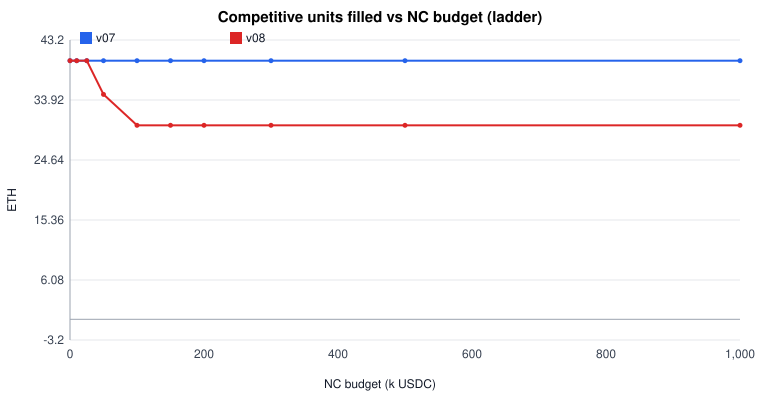

In [5]:
svg("nc_pricing_displacement.svg")  # competitive units displaced

In [6]:
show(load("nc_pricing"), ["rules","book","nc_budget_usdc","price","implied_apr","competitive_units","nc_units_in_pricing","nc_units_filled","nc_budget_unfilled_pct"], where=lambda r: r["book"] == "ladder")

rules | book   | nc_budget_usdc | price | implied_apr | competitive_units | nc_units_in_pricing | nc_units_filled | nc_budget_unfilled_pct
------+--------+----------------+-------+-------------+-------------------+---------------------+-----------------+-----------------------
  v07 | ladder |              0 | 3,285 |       1.825 |                40 |                   0 |               0 |                      0
  v07 | ladder |          1e+04 | 3,285 |       1.825 |                40 |                   0 |               0 |                    100
  v07 | ladder |        2.5e+04 | 3,285 |       1.825 |                40 |                   0 |               0 |                    100
  v07 | ladder |          5e+04 | 3,285 |       1.825 |                40 |                   0 |               0 |                    100
  v07 | ladder |          1e+05 | 3,285 |       1.825 |                40 |                   0 |               0 |                    100
  v07 | ladder |        1.5

### NC share cap sweep (25 / 33 / 50 %)

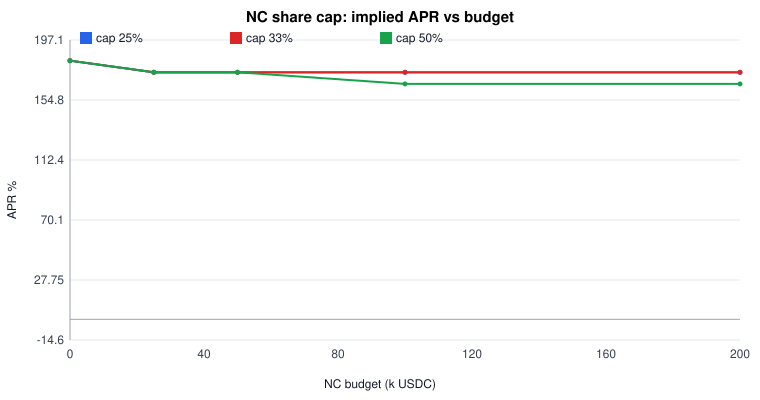

In [7]:
svg("nc_cap_sweep.svg")  # cap sweep

In [8]:
show(load("nc_cap_sweep"))

nc_cap_bps | nc_budget_usdc | price | implied_apr | competitive_units | nc_units
-----------+----------------+-------+-------------+-------------------+---------
     2,500 |              0 | 3,285 |       1.825 |                40 |        0
     2,500 |        2.5e+04 | 3,290 |       1.743 |                40 |     7.61
     2,500 |          5e+04 | 3,290 |       1.743 |                40 |       10
     2,500 |          1e+05 | 3,290 |       1.743 |                40 |       10
     2,500 |          2e+05 | 3,290 |       1.743 |                40 |       10
     3,300 |              0 | 3,285 |       1.825 |                40 |        0
     3,300 |        2.5e+04 | 3,290 |       1.743 |                40 |     7.61
     3,300 |          5e+04 | 3,290 |       1.743 |              36.8 |    12.14
     3,300 |          1e+05 | 3,290 |       1.743 |              36.8 |    12.14
     3,300 |          2e+05 | 3,290 |       1.743 |              36.8 |    12.14
     5,000 |              0 

## Wash trading (AUDIT M-2) and the dilution attack it exposes
An attacker self-trades at K − 1 and **defaults** (holding both R and C, the asset comes straight back). Under v0.7 the pool VWAP is pulled to K and the honest borrower's fee collapses. Under v0.8 the honest borrower's fee is untouched and the protocol earns the trade fee. **But in both versions the attacker profits**: the defaulted units share the honest borrower's repaid K pro rata.

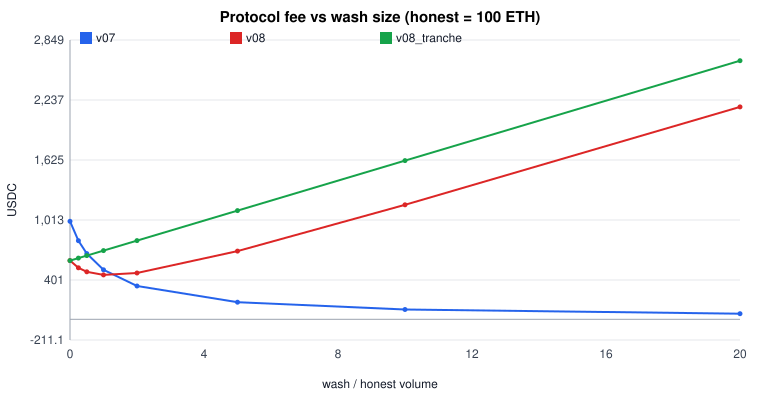

In [9]:
svg("fee_wash_fee.svg")  # protocol fee vs wash size

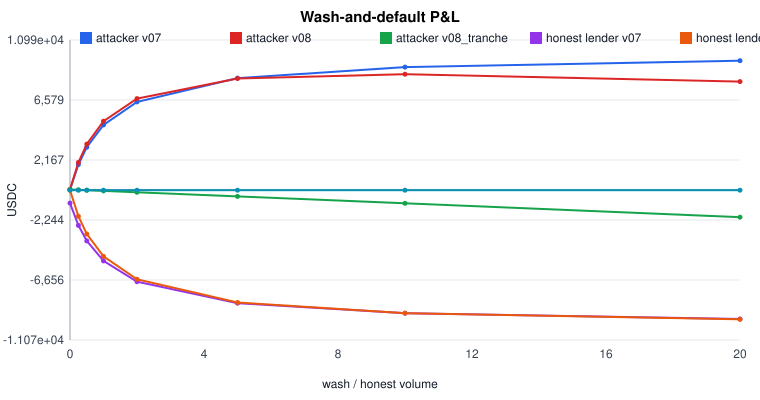

In [10]:
svg("fee_wash_pnl.svg")  # wash-and-default P&L

In [11]:
show(load("fee_wash"), ["rules","wash_multiple","vwap","protocol_fee_total","fee_lost_pct","attacker_pnl_usdc","honest_lender_pnl_usdc"])

rules       | wash_multiple | vwap  | protocol_fee_total | fee_lost_pct | attacker_pnl_usdc | honest_lender_pnl_usdc
------------+---------------+-------+--------------------+--------------+-------------------+-----------------------
        v07 |             0 | 3,300 |              1,000 |            0 |                 0 |                 -1,000
        v07 |          0.25 | 3,320 |                802 |         19.8 |             1,840 |                 -2,642
        v07 |           0.5 | 3,333 |                670 |           33 |             3,110 |                 -3,780
        v07 |             1 | 3,350 |                505 |         49.5 |             4,748 |                 -5,252
        v07 |             2 | 3,366 |                340 |           66 |             6,440 |                 -6,780
        v07 |             5 | 3,382 |                175 |         82.5 |             8,188 |                 -8,362
        v07 |            10 | 3,390 |                100 |      

### Dilution-fix variants
A = per-batch C (each batch its own tranche); B = the band applied to competitive clearing.

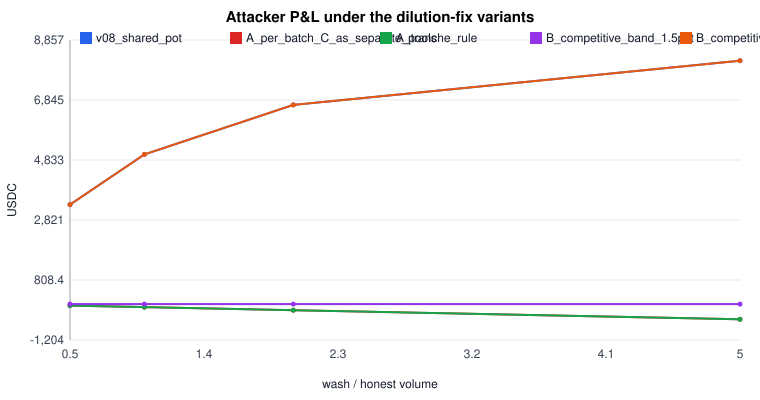

In [12]:
svg("dilution_variants.svg")  # attacker P&L under the variants

In [13]:
show(load("dilution_variants"))

variant                         | wash_multiple | attacker_pnl_usdc | honest_lender_pnl_usdc | honest_fill_blocked
--------------------------------+---------------+-------------------+------------------------+--------------------
                 v08_shared_pot |           0.5 |             3,336 |                 -3,271 |               false
A_per_batch_C_as_separate_pools |           0.5 |            -50.98 |                  -49.5 |               false
                 A_tranche_rule |           0.5 |            -50.98 |                  -49.5 |               false
      B_competitive_band_1.5pct |           0.5 |                 0 |                  -49.5 |                true
        B_competitive_band_8pct |           0.5 |             3,336 |                 -3,271 |               false
                 v08_shared_pot |             1 |             5,019 |                 -4,923 |               false
A_per_batch_C_as_separate_pools |             1 |              -102 |           

## Revenue magnitudes (closed form, BLUEPRINT §8)

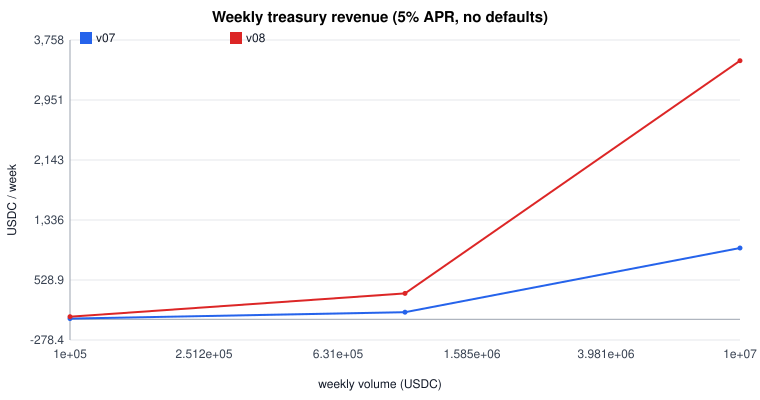

In [14]:
svg("revenue.svg")  # weekly treasury revenue

In [15]:
show(load("revenue"), ["rules","weekly_volume_usdc","apr","default_ratio","spread_share_usdc","trade_fee_usdc","treasury_weekly_usdc","treasury_yearly_usdc"], where=lambda r: r["apr"] == "0.05")

rules | weekly_volume_usdc | apr  | default_ratio | spread_share_usdc | trade_fee_usdc | treasury_weekly_usdc | treasury_yearly_usdc
------+--------------------+------+---------------+-------------------+----------------+----------------------+---------------------
  v07 |              1e+05 | 0.05 |             0 |             9.589 |              0 |                9.589 |                498.6
  v07 |              1e+05 | 0.05 |           0.1 |              8.63 |              0 |                 8.63 |                448.8
  v07 |              1e+05 | 0.05 |           0.3 |             6.712 |              0 |                6.712 |                  349
  v07 |          1,000,000 | 0.05 |             0 |             95.89 |              0 |                95.89 |                4,986
  v07 |          1,000,000 | 0.05 |           0.1 |              86.3 |              0 |                 86.3 |                4,488
  v07 |          1,000,000 | 0.05 |           0.3 |             67.12